In [1]:
!pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 34.9 MB/s eta 0:00:00


In [2]:
!pip install tqdm

# Washout Phase Analysis

The first step in the implementation of the quantum reservoir computer is to verify the **echo-state** (**washout**) property, namely that the long-time dynamics becomes independent of the initial state. To test this property, two different initial cavity states are considered: the vacuum state, $|0\rangle$, and a coherent state, $|\alpha\rangle$. Both states are then driven by exactly the same sequence of random inputs $\{\beta_i\}$ while evolving according to the unconditional Lindblad master equation derived in the previous section,

The dynamics of the reservoir is governed by the unconditional Lindblad master equation

$$
\frac{d\rho}{dt}
=
-i[H,\rho]
+
\kappa\,\mathcal{D}[a]\rho
+
\gamma\,\mathcal{D}[P_{\mathrm{even}}]\rho
+
\gamma\,\mathcal{D}[P_{\mathrm{odd}}]\rho,
$$

where the Hamiltonian

$$
H=i\left(\beta_i a^\dagger-\beta_i^*a\right)
$$

describes the coherent displacement associated with the input sequence, while the Lindblad dissipator is defined as

$$
\mathcal{D}[L]\rho
=
L\rho L^\dagger
-
\frac{1}{2}
\left\{
L^\dagger L,\rho
\right\}.
$$

The operator $a$ accounts for photon-loss dissipation, whereas

$$
P_{\mathrm{even}}
=
\frac{I+\Pi}{2},
\qquad
P_{\mathrm{odd}}
=
\frac{I-\Pi}{2},
$$

are the projectors onto the even- and odd-parity subspaces, respectively, describing the continuous parity measurement.

For each input, the master equation is integrated over a fixed time interval $dt$, and the final density matrix is used as the initial condition for the next input, thereby reproducing the sequential operation of a quantum reservoir. At the end of each interval, the average photon number

$$
\langle n\rangle_i
=
\mathrm{Tr}(a^\dagger a\,\rho_i)
$$

is computed for both evolutions, and the quantity

$$
\left|
\langle n\rangle_1
-
\langle n\rangle_2
\right|
$$

which measures the distance between the two reservoir trajectories that originate from different initial conditions but receive exactly the same sequence of inputs. If this difference converges to zero, the reservoir has effectively forgotten its initial condition, demonstrating the washout property required for reservoir computing.


This analysis directly extends the continuous parity-monitoring dynamics studied in **Steps 2 and 3**. There, the competition between coherent displacement and continuous parity measurement was investigated in order to characterize the unconditional evolution of the cavity field. Here, exactly** the same physical model is employed as a quantum reservoir**. The coherent displacement continuously injects information through the input sequence $\{\beta_i\}$, while photon losses and parity measurements introduce dissipation and decoherence that progressively erase the dependence on the initial state.

## Influence of Photon Loss

Photon-loss dissipation is introduced through the Lindblad operator

$$
L=\sqrt{\kappa}\,a.
$$


- **Horizontal axis:** input step, corresponding to the successive random inputs applied to the reservoir.
- **Vertical axis:** absolute difference between the average photon numbers of the two trajectories,
  $$
  \left|\langle n\rangle_1-\langle n\rangle_2\right|,
  $$
  which quantifies how strongly the current reservoir state still depends on its initial preparation.

 For $\kappa=0$, the difference between the two trajectories remains finite over the entire evolution, indicating that the reservoir retains a persistent memory of its initial state. In the absence of dissipation, the coherent displacement alone cannot erase the information stored in the initial condition.

As the photon-loss rate increases, the difference decays progressively towards zero. Larger values of $\kappa$ accelerate this convergence, demonstrating that dissipation continuously removes information about the initial preparation. Consequently, after a sufficiently large number of input steps, the reservoir dynamics becomes determined almost exclusively by the input sequence rather than by the initial state, thereby satisfying the washout (echo-state) condition required for quantum reservoir computing.

progreso:: 100%|██████████| 5/5 [03:43<00:00, 44.61s/it]


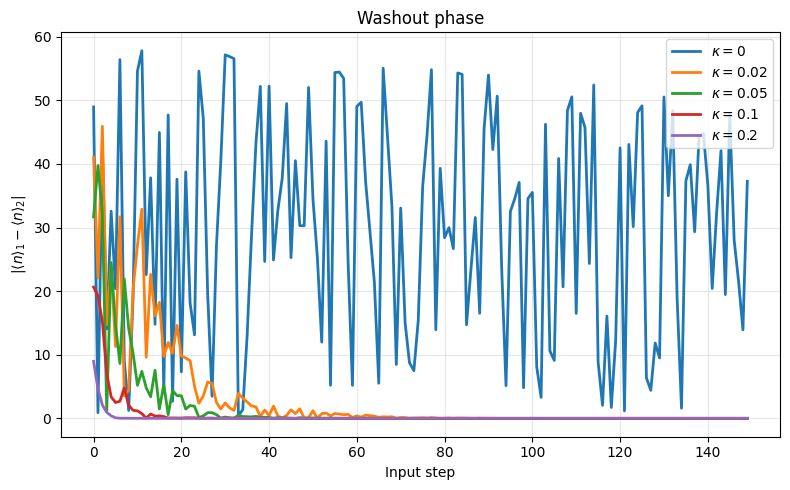

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from tqdm import tqdm

# Parameters


N = 80

dt = 10         # duration of each input
n_inputs = 150

kappa_list = [0, 0.02, 0.05, 0.1, 0.2]

# identical random input sequence for both evolutions
beta = np.random.uniform(0, 1, n_inputs)


# Operators


a = qt.destroy(N)
n_op = a.dag() * a

times = np.linspace(0, dt, 80)



psi1 = qt.basis(N, 0)
psi2 = qt.coherent(N, 5)



plt.figure(figsize=(8,5))

for kappa in tqdm(kappa_list,desc="progreso:"):

    c_ops = []

    if kappa > 0:
        c_ops = [np.sqrt(kappa) * a]

    state1 = psi1
    state2 = psi2

    n1 = []
    n2 = []

    for b in beta:

        # Hamiltonian for this input
        H = 1j * (b * a.dag() - b * a)

        # evolve first state
        result1 = qt.mesolve(
            H,
            state1,
            times,
            c_ops=c_ops,
            e_ops=[n_op],
            options={"store_states": True}
        )

        state1 = result1.states[-1]
        n1.append(result1.expect[0][-1])

        # evolve second state
        result2 = qt.mesolve(
            H,
            state2,
            times,
            c_ops=c_ops,
            e_ops=[n_op],
            options={"store_states": True}
        )

        state2 = result2.states[-1]
        n2.append(result2.expect[0][-1])

    n1 = np.array(n1)
    n2 = np.array(n2)

    plt.plot(np.abs(n1 - n2),
             lw=2,
             label=fr"$\kappa={kappa}$")

plt.xlabel("Input step")
plt.ylabel(r"$|\langle n\rangle_1-\langle n\rangle_2|$")
plt.title("Washout phase")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Continuous parity monitoring + photon-loss dissipation



When continuous parity monitoring is also included, the dynamics becomes

\begin{equation}
\frac{d\rho}{dt}
=
-i[H,\rho]
+
\kappa\mathcal{D}[a]\rho
+
\gamma\mathcal{D}[P_{\mathrm{even}}]\rho
+
\gamma\mathcal{D}[P_{\mathrm{odd}}]\rho.
\end{equation}

Unlike photon losses, the parity projectors do not change the photon-number populations, since they neither create nor annihilate photons. Instead, they continuously destroy the quantum coherences between the even- and odd-parity subspaces. Consequently, the reservoir loses information about its initial quantum state much more rapidly. This behavior is clearly observed in the washout curves, where the difference

\begin{equation}
\left|
\langle n\rangle_1
-
\langle n\rangle_2
\right|
\end{equation}

decays to zero after only a few input steps, even in the absence of photon losses ($\kappa=0$). As the photon-loss rate is increased, both dissipation and parity-induced decoherence cooperate, producing an even faster convergence.


100%|██████████| 5/5 [06:17<00:00, 75.60s/it]


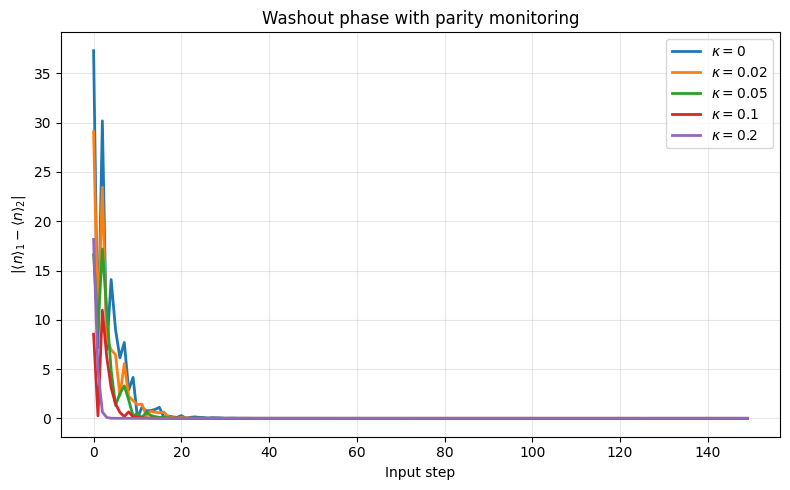

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from tqdm import tqdm



N = 80

dt = 10
n_inputs = 150

kappa_list = [0, 0.02, 0.05, 0.1, 0.2]

gamma = 0.05        # parity measurement rate

beta = np.random.uniform(0,1,n_inputs)


# Operators


a = qt.destroy(N)
n_op = a.dag()*a

I = qt.qeye(N)

# parity operator
parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2

times = np.linspace(0, dt, 80)


# Initial states


psi1 = qt.basis(N,0)
psi2 = qt.coherent(N,5)




plt.figure(figsize=(8,5))

for kappa in tqdm(kappa_list):

    # Lindblad operators
    c_ops = []

    # photon loss
    if kappa > 0:
        c_ops.append(np.sqrt(kappa)*a)

    # parity monitoring
    c_ops.append(np.sqrt(gamma)*P_even)
    c_ops.append(np.sqrt(gamma)*P_odd)

    state1 = psi1
    state2 = psi2

    n1 = []
    n2 = []

    for b in beta:

        # coherent displacement
        H = 1j*(b*a.dag() - b*a)

        # evolution from first initial state
        result1 = qt.mesolve(
            H,
            state1,
            times,
            c_ops=c_ops,
            options={"store_states": True}
        )

        state1 = result1.states[-1]
        n1.append(qt.expect(n_op, state1))

        # evolution from second initial state
        result2 = qt.mesolve(
            H,
            state2,
            times,
            c_ops=c_ops,
            options={"store_states": True}
        )

        state2 = result2.states[-1]
        n2.append(qt.expect(n_op, state2))

    plt.plot(
        np.abs(np.array(n1)-np.array(n2)),
        lw=2,
        label=fr"$\kappa={kappa}$"
    )

plt.xlabel("Input step")
plt.ylabel(r"$|\langle n\rangle_1-\langle n\rangle_2|$")
plt.title("Washout phase with parity monitoring")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

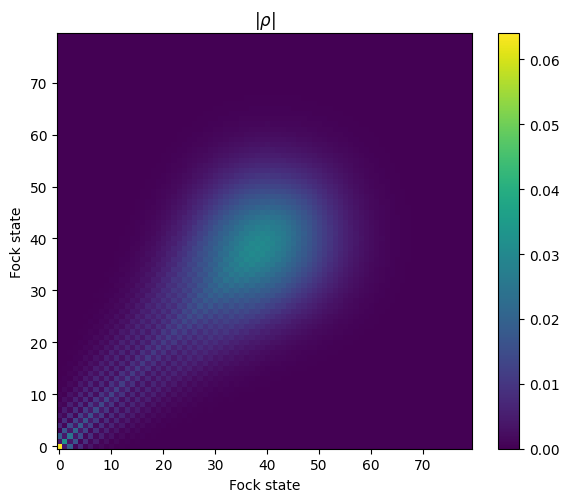

In [ ]:
rho = state2

plt.figure(figsize=(6,5))

plt.imshow(np.abs(rho.full()),
           origin="lower",
           cmap="viridis")

plt.xlabel("Fock state")
plt.ylabel("Fock state")
plt.title(r"$|\rho|$")
plt.colorbar()

plt.tight_layout()
plt.show()

## Influence of Continuous Parity Monitoring

After identifying an appropriate photon-loss rate, the next step is to investigate the effect of the **continuous parity measurement strength** on the washout dynamics. In this analysis, the photon-loss rate is fixed at

$$
\kappa=0.1,
$$

while the parity monitoring rate is varied over a broad range of values,

$$
\gamma\in\{0,\;0.01,\;0.02,\;0.05,\;0.1,\;0.2,\;0.5\}.
$$




100%|██████████| 7/7 [07:48<00:00, 66.96s/it]


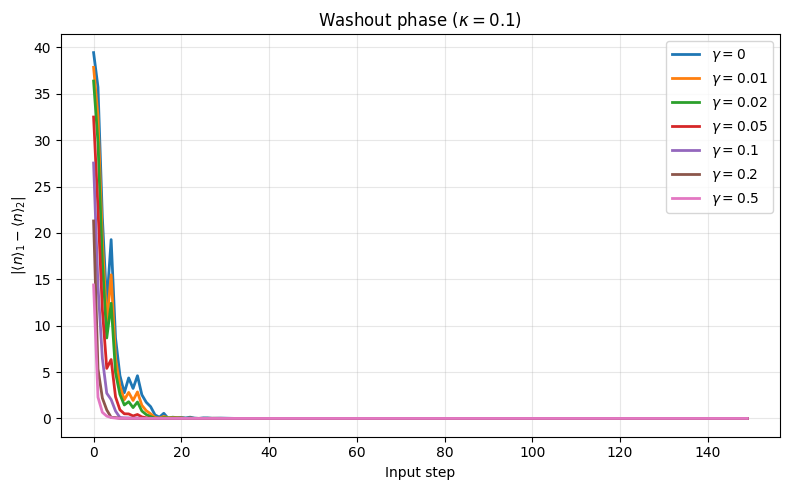

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from tqdm import tqdm


N = 80

dt = 10
n_inputs = 150

kappa = 0.1                    # fixed
gamma_list = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]

beta = np.random.uniform(0,1,n_inputs)

a = qt.destroy(N)
n_op = a.dag()*a

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2

times = np.linspace(0, dt, 80)


psi1 = qt.basis(N,0)
psi2 = qt.coherent(N,5)



plt.figure(figsize=(8,5))

for gamma in tqdm(gamma_list):

    c_ops = []

    # photon loss
    c_ops.append(np.sqrt(kappa)*a)

    # parity measurement
    if gamma > 0:
        c_ops.append(np.sqrt(gamma)*P_even)
        c_ops.append(np.sqrt(gamma)*P_odd)

    state1 = psi1
    state2 = psi2

    diff = []

    for b in beta:

        H = 1j*(b*a.dag() - b*a)

        result1 = qt.mesolve(
            H,
            state1,
            times,
            c_ops=c_ops,
            options={"store_states":True}
        )

        state1 = result1.states[-1]
        n1 = qt.expect(n_op,state1)

        result2 = qt.mesolve(
            H,
            state2,
            times,
            c_ops=c_ops,
            options={"store_states":True}
        )

        state2 = result2.states[-1]
        n2 = qt.expect(n_op,state2)

        diff.append(abs(n1-n2))

    plt.plot(
        diff,
        lw=2,
        label=fr"$\gamma={gamma}$"
    )

plt.xlabel("Input step")
plt.ylabel(r"$|\langle n\rangle_1-\langle n\rangle_2|$")
plt.title(r"Washout phase ($\kappa=0.1$)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Influence of the Input Duration

Other hyperparameter considered in the washout analysis is the **input duration** $dt$. This parameter determines the time during which each input amplitude $\beta_i$ acts on the reservoir before being replaced by the next one.

Throughout this study, the dissipation parameters are fixed to

$$
\kappa=0.1,
\qquad
\gamma=0.05,
$$

while the input duration is varied according to

$$
dt\in\{1,\;2,\;5,\;10,\;15,\;20\}.
$$




The obtained results reveal the important role played by the input duration. For short interaction times ($dt=1$ or $dt=2$), each input acts on the reservoir for only a brief period before being replaced by the next one. Consequently, the dissipative dynamics does not have sufficient time to erase the memory of the initial state, leading to a relatively slow convergence.

As $dt$ increases, the reservoir is allowed to evolve for a longer time under each input. The combined action of coherent driving and dissipation therefore drives the two trajectories towards the same dynamical state much more rapidly.

100%|██████████| 6/6 [06:21<00:00, 63.60s/it]


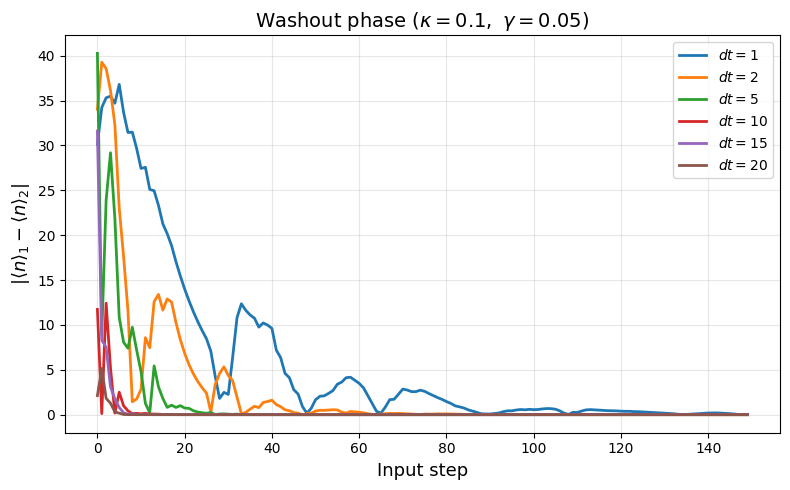

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from tqdm import tqdm


# Parameters


N = 80
n_inputs = 150

dt_list = [1, 2, 5, 10, 15, 20]

kappa = 0.1
gamma = 0.05

beta = np.random.uniform(0,1,n_inputs)


#operators

a = qt.destroy(N)
n_op = a.dag()*a

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2


# Initial states

psi1 = qt.basis(N,0)
psi2 = qt.coherent(N,5)

# Collapse operators

c_ops = [
    np.sqrt(kappa)*a,
    np.sqrt(gamma)*P_even,
    np.sqrt(gamma)*P_odd
]



plt.figure(figsize=(8,5))

for dt in tqdm(dt_list):

    times = np.linspace(0, dt, 80)

    state1 = psi1
    state2 = psi2

    n1 = []
    n2 = []

    for b in beta:

        H = 1j*(b*a.dag() - b*a)

        result1 = qt.mesolve(
            H,
            state1,
            times,
            c_ops=c_ops,
            options={"store_states": True}
        )

        state1 = result1.states[-1]
        n1.append(qt.expect(n_op, state1))

        result2 = qt.mesolve(
            H,
            state2,
            times,
            c_ops=c_ops,
            options={"store_states": True}
        )

        state2 = result2.states[-1]
        n2.append(qt.expect(n_op, state2))

    plt.plot(
        np.abs(np.array(n1)-np.array(n2)),
        lw=2,
        label=fr"$dt={dt}$"
    )

plt.xlabel("Input step", fontsize=13)
plt.ylabel(r"$|\langle n\rangle_1-\langle n\rangle_2|$", fontsize=13)
plt.title(r"Washout phase ($\kappa=0.1,\ \gamma=0.05$)", fontsize=14)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Short-Term Memory Task

Once the washout property has been verified and the reservoir hyperparameters have been studied, the next step is to evaluate the computational capability of the reservoir through the **Short-Term Memory (STM)** benchmark.

The STM task is the standard linear memory benchmark used in reservoir computing. A sequence of random input values

$$
\{\beta_i\},\qquad
\beta_i\in(0,1),
$$

is sequentially injected into the reservoir. At every input step, the cavity evolves according to

$$
\frac{d\rho}{dt}
=
-i[H,\rho]
+
\kappa\mathcal{D}[a]\rho
+
\gamma\mathcal{D}[P_{\rm even}]\rho
+
\gamma\mathcal{D}[P_{\rm odd}]\rho,
$$

where

$$
H=i(\beta_i a^\dagger-\beta_i a),
$$

and

$$
\mathcal{D}[L]\rho
=
L\rho L^\dagger
-
\frac12
\left\{
L^\dagger L,\rho
\right\}.
$$

After the evolution associated with each input, the final density matrix is used as the initial state for the next input, so that the reservoir continuously accumulates information from the previous inputs.

Rather than using only the mean photon number, the **readout layer** is constructed from a collection of expectation values of nonlinear observables. The resulting feature vector therefore provides a nonlinear representation of the reservoir state that is subsequently processed by a **linear regressor**.

For a given **delay $\tau$**, the STM task consists of reconstructing the input applied $\tau$ time steps earlier,

$$
y_i=\beta_{i-\tau}.
$$

The reservoir outputs are fitted using **Ridge regression**, and the reconstruction accuracy is quantified through the squared Pearson correlation coefficient,

$$
C(\tau)
=
\frac{\mathrm{cov}(y,\hat y)^2}
{\sigma_y^2\,\sigma_{\hat y}^2},
$$

where $y$ denotes the target sequence and $\hat y$ the predictions of the linear readout. The quantity $C(\tau)$ is known as the **memory capacity**. Its maximum value is

$$
C=1,
$$

which corresponds to perfect reconstruction of the delayed input.

**dt = 10**

100%|██████████| 2000/2000 [08:19<00:00,  4.01it/s]
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.04077e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.04077e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.04077e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.04077e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.04077e-18): result may not be accurate.
  return f(

(2000, 43)


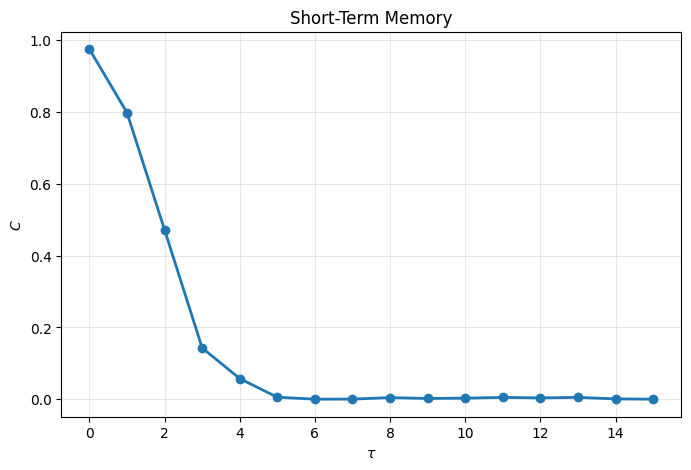

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from sklearn.linear_model import Ridge
from tqdm import tqdm



N = 80

dt = 10
n_inputs = 2000

kappa = 0.1
gamma = 0.05

washout = 100
max_delay = 15
train_frac = 0.7

beta = np.random.uniform(0,1,n_inputs)


# Operators


a = qt.destroy(N)

n_op = a.dag()*a

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I+parity)/2
P_odd  = (I-parity)/2


# Observables

hermitian_ops = [

    n_op,
    n_op**2,
    n_op**3,
    n_op**4,

    parity,
    P_even,
    P_odd

]

complex_ops = [

    a.dag(),
    a.dag()**2,
    a.dag()**3,
    a.dag()**4,
    a.dag()**5,

    n_op*a.dag(),
    n_op*a,

    n_op*(a.dag()**2),
    n_op*(a**2),

    n_op*(a.dag()**3),
    n_op*(a**3),

    n_op*(a.dag()**4),
    n_op*(a**4),

    n_op*(a.dag()**5),
    n_op*(a**5),

    (n_op**2)*a.dag(),
    (n_op**2)*a,

    (n_op**2)*(a.dag()**2)

]

e_ops = hermitian_ops + complex_ops


# Collapse operators


c_ops = [

    np.sqrt(kappa)*a,
    np.sqrt(gamma)*P_even,
    np.sqrt(gamma)*P_odd

]

times = np.linspace(0,dt,80)


# Initial state

state = qt.basis(N,0)


# Reservoir


features = []

for b in tqdm(beta):

    H = 1j*(b*a.dag()-b*a)

    result = qt.mesolve(

        H,
        state,
        times,
        c_ops=c_ops,
        e_ops=e_ops,
        options={"store_states":True}

    )

    state = result.states[-1]

    row = []

    # Hermitian observables

    for k in range(len(hermitian_ops)):

        row.append(np.real(result.expect[k][-1]))

    # Complex observables

    start = len(hermitian_ops)

    for k in range(len(complex_ops)):

        value = result.expect[start+k][-1]

        row.append(np.real(value))
        row.append(np.imag(value))

    features.append(row)

features = np.array(features)

print(features.shape)


# STM

memory_curve = []

for tau in range(max_delay+1):

    X = features[washout:]

    y = beta[washout-tau:n_inputs-tau]

    split = int(train_frac*len(X))

    X_train = X[:split]
    X_test  = X[split:]

    y_train = y[:split]
    y_test  = y[split:]

    reg = Ridge(alpha=1/20)

    reg.fit(X_train,y_train)

    prediction = reg.predict(X_test)

    r = np.corrcoef(prediction,y_test)[0,1]

    C = 0 if np.isnan(r) else r**2

    memory_curve.append(C)




plt.figure(figsize=(8,5))

plt.plot(

    range(max_delay+1),
    memory_curve,
    "-o",
    lw=2

)

plt.xlabel(r"$\tau$")
plt.ylabel(r"$C$")
plt.title("Short-Term Memory")

plt.grid(alpha=0.3)

plt.show()

 **dt = 5**

100%|██████████| 2000/2000 [05:18<00:00,  6.27it/s]
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.5794e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.5794e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.5794e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.5794e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.5794e-18): result may not be accurate.
  return f(*arra

(2000, 43)


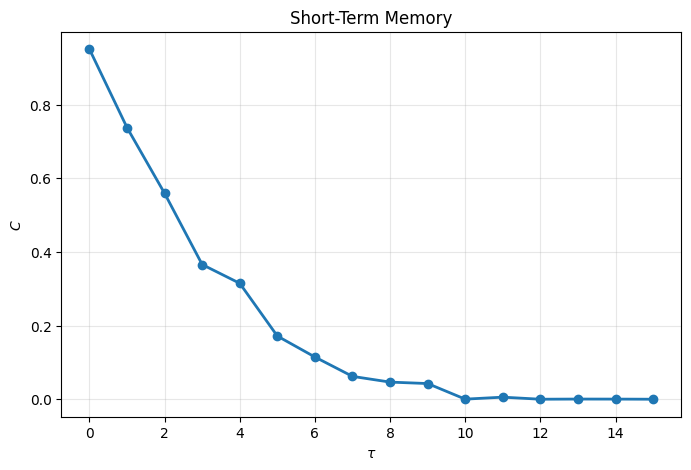

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from sklearn.linear_model import Ridge
from tqdm import tqdm



N = 80

dt = 5
n_inputs = 2000

kappa = 0.1
gamma = 0.05

washout = 100
max_delay = 15
train_frac = 0.7

beta = np.random.uniform(0,1,n_inputs)


# Operators


a = qt.destroy(N)

n_op = a.dag()*a

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I+parity)/2
P_odd  = (I-parity)/2


# Observables

hermitian_ops = [

    n_op,
    n_op**2,
    n_op**3,
    n_op**4,

    parity,
    P_even,
    P_odd

]

complex_ops = [

    a.dag(),
    a.dag()**2,
    a.dag()**3,
    a.dag()**4,
    a.dag()**5,

    n_op*a.dag(),
    n_op*a,

    n_op*(a.dag()**2),
    n_op*(a**2),

    n_op*(a.dag()**3),
    n_op*(a**3),

    n_op*(a.dag()**4),
    n_op*(a**4),

    n_op*(a.dag()**5),
    n_op*(a**5),

    (n_op**2)*a.dag(),
    (n_op**2)*a,

    (n_op**2)*(a.dag()**2)

]

e_ops = hermitian_ops + complex_ops


# Collapse operators


c_ops = [

    np.sqrt(kappa)*a,
    np.sqrt(gamma)*P_even,
    np.sqrt(gamma)*P_odd

]

times = np.linspace(0,dt,80)


# Initial state

state = qt.basis(N,0)


# Reservoir


features = []

for b in tqdm(beta):

    H = 1j*(b*a.dag()-b*a)

    result = qt.mesolve(

        H,
        state,
        times,
        c_ops=c_ops,
        e_ops=e_ops,
        options={"store_states":True}

    )

    state = result.states[-1]

    row = []

    # Hermitian observables

    for k in range(len(hermitian_ops)):

        row.append(np.real(result.expect[k][-1]))

    # Complex observables

    start = len(hermitian_ops)

    for k in range(len(complex_ops)):

        value = result.expect[start+k][-1]

        row.append(np.real(value))
        row.append(np.imag(value))

    features.append(row)

features = np.array(features)

print(features.shape)


# STM

memory_curve = []

for tau in range(max_delay+1):

    X = features[washout:]

    y = beta[washout-tau:n_inputs-tau]

    split = int(train_frac*len(X))

    X_train = X[:split]
    X_test  = X[split:]

    y_train = y[:split]
    y_test  = y[split:]

    reg = Ridge(alpha=1/20)

    reg.fit(X_train,y_train)

    prediction = reg.predict(X_test)

    r = np.corrcoef(prediction,y_test)[0,1]

    C = 0 if np.isnan(r) else r**2

    memory_curve.append(C)




plt.figure(figsize=(8,5))

plt.plot(

    range(max_delay+1),
    memory_curve,
    "-o",
    lw=2

)

plt.xlabel(r"$\tau$")
plt.ylabel(r"$C$")
plt.title("Short-Term Memory")

plt.grid(alpha=0.3)

plt.show()



100%|██████████| 2000/2000 [05:00<00:00,  6.67it/s]
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(

(2000, 43)


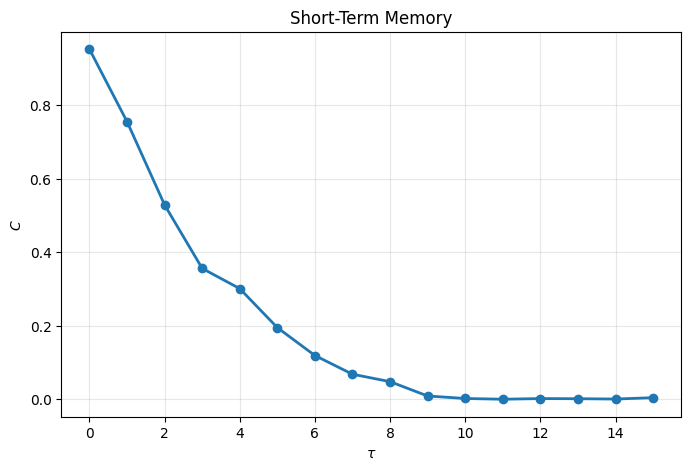

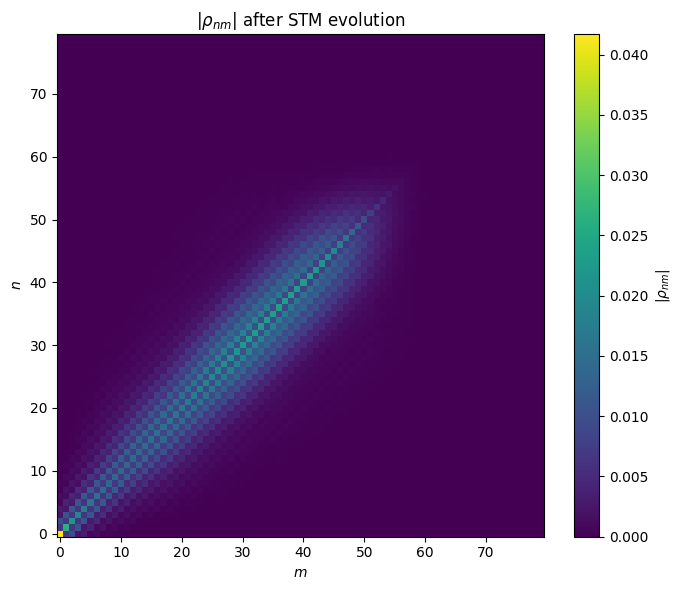

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from sklearn.linear_model import Ridge
from tqdm import tqdm



N = 80

dt = 5
n_inputs = 2000

kappa = 0.1
gamma = 0.05

washout = 100
max_delay = 15
train_frac = 0.7

beta = np.random.uniform(0,1,n_inputs)


# Operators


a = qt.destroy(N)

n_op = a.dag()*a

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I+parity)/2
P_odd  = (I-parity)/2


# Observables

hermitian_ops = [

    n_op,
    n_op**2,
    n_op**3,
    n_op**4,

    parity,
    P_even,
    P_odd

]

complex_ops = [

    a.dag(),
    a.dag()**2,
    a.dag()**3,
    a.dag()**4,
    a.dag()**5,

    n_op*a.dag(),
    n_op*a,

    n_op*(a.dag()**2),
    n_op*(a**2),

    n_op*(a.dag()**3),
    n_op*(a**3),

    n_op*(a.dag()**4),
    n_op*(a**4),

    n_op*(a.dag()**5),
    n_op*(a**5),

    (n_op**2)*a.dag(),
    (n_op**2)*a,

    (n_op**2)*(a.dag()**2)

]

e_ops = hermitian_ops + complex_ops


# Collapse operators


c_ops = [

    np.sqrt(kappa)*a,
    np.sqrt(gamma)*P_even,
    np.sqrt(gamma)*P_odd

]

times = np.linspace(0,dt,80)


# Initial state

state = qt.basis(N,0)


# Reservoir


features = []

for b in tqdm(beta):

    H = 1j*(b*a.dag()-b*a)

    result = qt.mesolve(

        H,
        state,
        times,
        c_ops=c_ops,
        e_ops=e_ops,
        options={"store_states":True}

    )

    state = result.states[-1]

    row = []

    # Hermitian observables

    for k in range(len(hermitian_ops)):

        row.append(np.real(result.expect[k][-1]))

    # Complex observables

    start = len(hermitian_ops)

    for k in range(len(complex_ops)):

        value = result.expect[start+k][-1]

        row.append(np.real(value))
        row.append(np.imag(value))

    features.append(row)

features = np.array(features)

print(features.shape)


# STM

memory_curve = []

for tau in range(max_delay+1):

    X = features[washout:]

    y = beta[washout-tau:n_inputs-tau]

    split = int(train_frac*len(X))

    X_train = X[:split]
    X_test  = X[split:]

    y_train = y[:split]
    y_test  = y[split:]

    reg = Ridge(alpha=1/20)

    reg.fit(X_train,y_train)

    prediction = reg.predict(X_test)

    r = np.corrcoef(prediction,y_test)[0,1]

    C = 0 if np.isnan(r) else r**2

    memory_curve.append(C)




plt.figure(figsize=(8,5))

plt.plot(

    range(max_delay+1),
    memory_curve,
    "-o",
    lw=2

)

plt.xlabel(r"$\tau$")
plt.ylabel(r"$C$")
plt.title("Short-Term Memory")

plt.grid(alpha=0.3)

plt.show()

rho = state

plt.figure(figsize=(7,6))

plt.imshow(
    np.abs(rho.full()),
    origin="lower",
    cmap="viridis",
    aspect="auto"
)

plt.xlabel(r"$m$")
plt.ylabel(r"$n$")
plt.title(r"$|\rho_{nm}|$ after STM evolution")

plt.colorbar(label=r"$|\rho_{nm}|$")

plt.tight_layout()
plt.show()

## How the choice of the feature vector influences the curves for the capacity of the short-term memory?

In [ ]:
def compute_features(beta, hermitian_ops, complex_ops):

    e_ops = hermitian_ops + complex_ops

    state = qt.basis(N,0)

    features = []

    for b in tqdm(beta, leave=False):

        H = 1j*(b*a.dag()-b*a)

        result = qt.mesolve(
            H,
            state,
            times,
            c_ops=c_ops,
            e_ops=e_ops,
            options={"store_states":True}
        )

        state = result.states[-1]

        row = []

        # Hermitian observables
        for k in range(len(hermitian_ops)):
            row.append(np.real(result.expect[k][-1]))

        # Complex observables
        start = len(hermitian_ops)

        for k in range(len(complex_ops)):
            value = result.expect[start+k][-1]
            row.append(np.real(value))
            row.append(np.imag(value))

        features.append(row)

    return np.array(features)

In [ ]:
def STM_capacity(features):

    memory_curve = []

    for tau in range(max_delay+1):

        X = features[washout:]
        y = beta[washout-tau:n_inputs-tau]

        split = int(train_frac*len(X))

        X_train = X[:split]
        X_test  = X[split:]

        y_train = y[:split]
        y_test  = y[split:]

        reg = Ridge(alpha=1/20)

        reg.fit(X_train,y_train)

        prediction = reg.predict(X_test)

        r = np.corrcoef(prediction,y_test)[0,1]

        C = 0 if np.isnan(r) else r**2

        memory_curve.append(C)

    return memory_curve

In [ ]:
herm = [n_op]
comp = []

features_n = compute_features(beta, herm, comp)
C_n = STM_capacity(features_n)

In [ ]:
herm = [
    n_op,
    n_op**2,
    n_op**3,
    n_op**4
]

comp = []

features_moments = compute_features(beta, herm, comp)
C_moments = STM_capacity(features_moments)

In [ ]:
herm = [
    parity,
    P_even,
    P_odd
]

comp = []

features_parity = compute_features(beta, herm, comp)
C_parity = STM_capacity(features_parity)

In [ ]:
herm = []

comp = [

    a.dag(),
    a.dag()**2,
    a.dag()**3,
    a.dag()**4,
    a.dag()**5

]

features_complex = compute_features(beta, herm, comp)
C_complex = STM_capacity(features_complex)

In [ ]:
herm = [

    n_op,
    n_op**2,
    n_op**3,
    n_op**4,

    parity,
    P_even,
    P_odd

]

comp = [

    a.dag(),
    a.dag()**2,
    a.dag()**3,
    a.dag()**4,
    a.dag()**5,

    n_op*a.dag(),
    n_op*a,

    n_op*(a.dag()**2),
    n_op*(a**2),

    n_op*(a.dag()**3),
    n_op*(a**3),

    n_op*(a.dag()**4),
    n_op*(a**4),

    n_op*(a.dag()**5),
    n_op*(a**5),

    (n_op**2)*a.dag(),
    (n_op**2)*a,

    (n_op**2)*(a.dag()**2)

]

features_all = compute_features(beta, herm, comp)
C_all = STM_capacity(features_all)

/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.44818e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/pytho

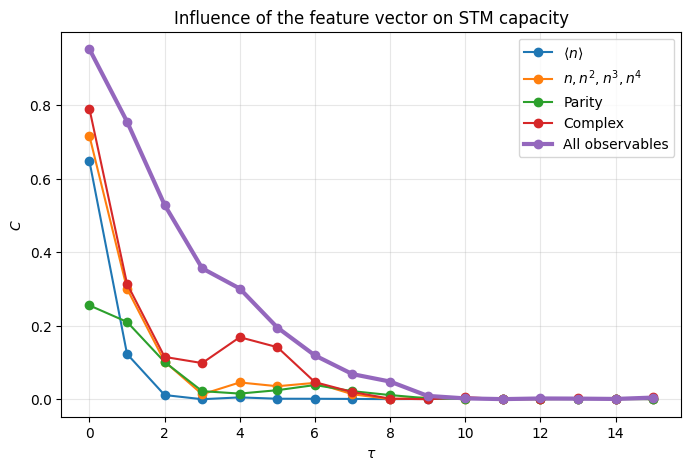

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(C_n, '-o', label=r'$\langle n\rangle$')

plt.plot(C_moments, '-o', label=r'$n,n^2,n^3,n^4$')

plt.plot(C_parity, '-o', label='Parity')

plt.plot(C_complex, '-o', label='Complex')

plt.plot(C_all, '-o', lw=3, label='All observables')

plt.xlabel(r'$\tau$')
plt.ylabel(r'$C$')

plt.title("Influence of the feature vector on STM capacity")

plt.grid(alpha=0.3)

plt.legend()

plt.show()